# Лабораторная работа №1. Иерархический кластерный анализ.

Выполнила Чуприна Анна.

In [104]:
#  Активируем библиотеки

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

import os

Начнем с того, что прочитаем представленную таблицу.

**Экономика городов.**

1) Данные описывают экономические условия в 48 городах мира в 1991 году.
Данные были собраны отделом экономических исследований банка Union
(Швейцария). Описаны экономические условия в 48 городах мира в 1991 году.

2) Число наблюдений: 48.
3) Названия переменных:

* Сity (Город): Название города.

* Работа (Work): Взвешенное среднее числа рабочих часов, сосчитанное по 12
профессиям.

* Цена (Price): Индекс цен 112 товаров и услуг, включая арендную плату за
жилье (значение для Цюриха взято за 100%).

* Заработная плата (Salary): Индекс заработной платы за час работы,
сосчитанный по 12 профессиям после налогов и вычетов (значение для Цюриха
взято за 100%).

Данные содержатся в файле Economics_of_Cities.сsv

In [105]:
dataset = pd.read_csv('Econom_Cities_data.csv',sep=';',decimal=',')
dataset.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


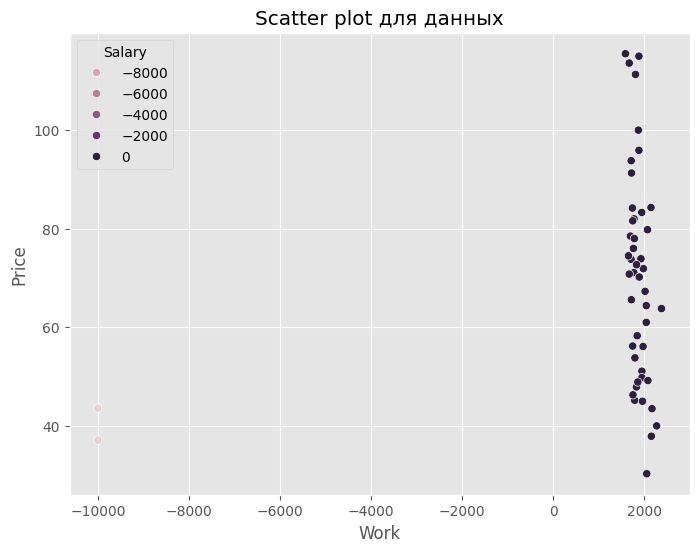

In [106]:
plt.figure(figsize=(8,6))
sns.scatterplot(x = dataset['Work'], y = dataset['Price'], hue = dataset['Salary'])
plt.title('Scatter plot для данных')
plt.show()

Видим два выброса, это незаполненные данные. Удалим их.

In [107]:
dataset = dataset[dataset['Work']>0]

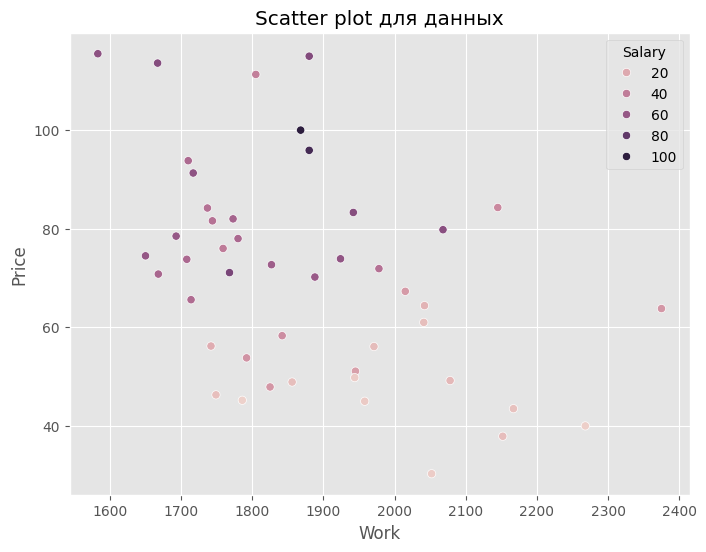

In [108]:
plt.figure(figsize=(8,6))
sns.scatterplot(x = dataset['Work'], y = dataset['Price'], hue = dataset['Salary'])
plt.title('Scatter plot для данных')
plt.show()

Заметим, что масштаб величин в колонках разный, следовательно, необходимо стандартизировать. Буду использовать `StandardScaler()`.


> Стандартизация (standardization, z-score normalization) центрирует признак относительно среднего и масштабирует его так, чтобы дисперсия стала равна единице. Формула преобразования:
$$x' = \frac{x - \mu}{\sigma},$$
где $$\mu = \frac{1}{n} \sum_{i=1}^n x_i, \quad \sigma = \sqrt{\frac{1}{n} \sum_{i=1}^n (x_i - \mu)^2}$$
[Стандартизация](http://www.machinelearning.ru/wiki/index.php?title=%D0%9D%D0%BE%D1%80%D0%BC%D0%B0%D0%BB%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_%D0%B8_%D1%81%D1%82%D0%B0%D0%BD%D0%B4%D0%B0%D1%80%D1%82%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_%D0%BF%D1%80%D0%B8%D0%B7%D0%BD%D0%B0%D0%BA%D0%BE%D0%B2)



In [109]:
scaler = StandardScaler()
X = scaler.fit_transform(dataset[['Work','Price','Salary']])
X = pd.DataFrame(X, index=dataset.index, columns=['Work','Price','Salary'])
X.head()

,Work,Price,Salary
0,-0.962166,-0.212712,0.386095
1,-0.509827,-0.770489,-0.373488
2,1.577891,-1.522069,-1.145323
3,0.997969,-1.881316,-1.398517
4,-0.996961,0.174896,0.447351


In [110]:
dataset.describe()

,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


Проводим кластеризацию, вычисляя Евклидово расстояние между точками, а расстояние между кластерами - по методу Уорда.

In [111]:
link = linkage(X, 'ward', 'euclidean')

Строим дендрограмму.

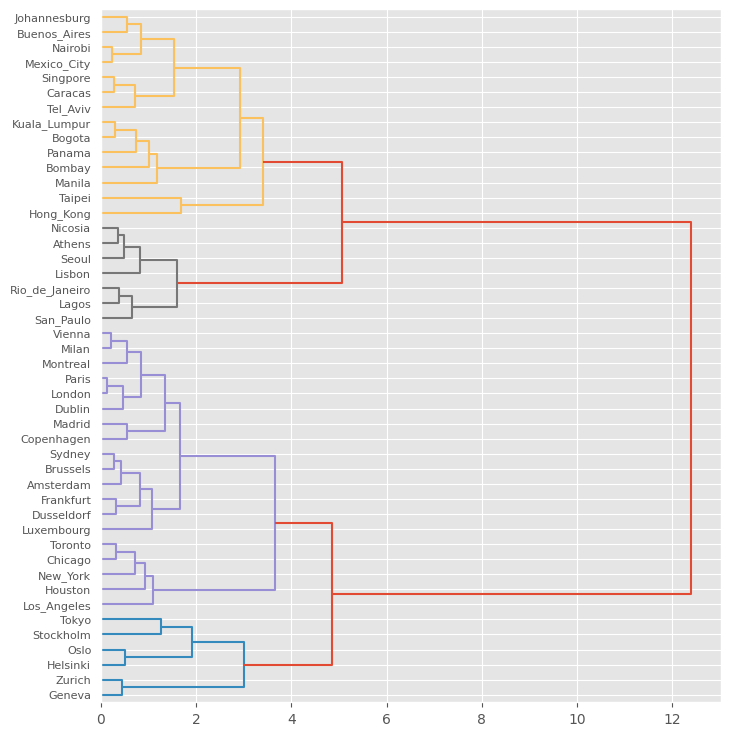

In [112]:
fig = plt.figure(figsize=(8,9))
dn = dendrogram(link, color_threshold = 4, labels=dataset['City'].values,orientation = "right")

Построю график каменистой осыпи.

In [113]:
dist = link[:, 2]
dist

array([ 0.13000932,  0.20992596,  0.24101549,  0.26638013,  0.27962161,
        0.28619313,  0.31145704,  0.31305006,  0.3489377 ,  0.38756772,
        0.419298  ,  0.44645167,  0.45306282,  0.4905399 ,  0.50930475,
        0.54142314,  0.54694673,  0.55560294,  0.6525312 ,  0.70695573,
        0.71322146,  0.73106836,  0.80923253,  0.81996004,  0.83440954,
        0.83591396,  0.92010068,  1.00797757,  1.07317494,  1.09798639,
        1.18557963,  1.2661125 ,  1.34552527,  1.5346713 ,  1.60218207,
        1.65009621,  1.67120837,  1.9067302 ,  2.91093293,  2.99369803,
        3.40166518,  3.65965497,  4.85967779,  5.06109685, 12.40027153])

Text(0, 0.5, 'Расстояние')

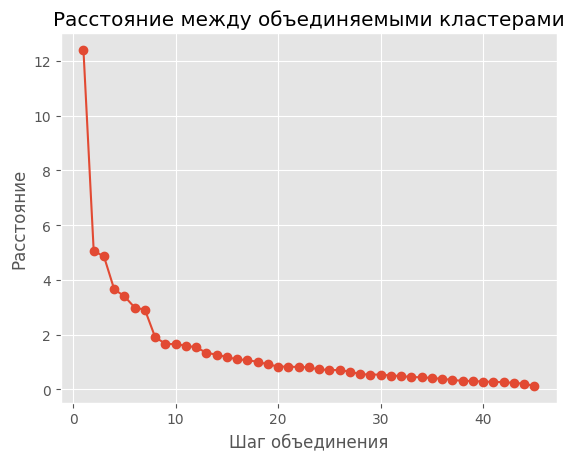

In [114]:
dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

Распределяю страны по кластерам, добавляя столбец в таблицу.

Добавляю колонку 'cluster' - номер кластера.

In [115]:
dataset['cluster'] = fcluster(link,4,criterion = 'distance')

Группирую по кластерам и смотрю на среднее значение.

In [116]:
dataset.groupby('cluster').mean(numeric_only=True)

,Work,Price,Salary
cluster,,,
1,1780.500000,108.550000,71.300000
2,1792.000000,77.526316,55.157895
3,1798.857143,50.942857,19.214286
4,2082.357143,53.121429,14.914286


Получили 4 кластера.

**1 кластер** - страны с высокой зарплатой и очень высокой стоимостью жизни, наименьшим числом рабочих часов.

**2 кластер** - страны среднего уровня - зарплата не сильно отстает от стоимости жизни.

**3 кластер** - страны с невысокой зарплатой, средней ценой жизни, однако люди не сильно перерабатывают.

**4 кластер** - страны с низкой зарплатой, где количество рабочих часов велико.

In [117]:
dataset.groupby('cluster').size()

,0
cluster,
1,6
2,19
3,7
4,14


In [118]:
for cluster in [1,2,3,4]:
  print(f'cluster: {cluster}')
  for el in dataset[dataset['cluster']==cluster].index:
    print(dataset.loc[el, 'City'])
  print('')

cluster: 1
Geneva
Helsinki
Oslo
Stockholm
Tokyo
Zurich

cluster: 2
Amsterdam
Brussels
Chicago
Copenhagen
Dublin
Dusseldorf
Frankfurt
Houston
London
Los_Angeles
Luxembourg
Madrid
Milan
Montreal
New_York
Paris
Sydney
Toronto
Vienna

cluster: 3
Athens
Lagos
Lisbon
Nicosia
Rio_de_Janeiro
San_Paulo
Seoul

cluster: 4
Bogota
Bombay
Buenos_Aires
Caracas
Hong_Kong
Johannesburg
Kuala_Lumpur
Manila
Mexico_City
Nairobi
Panama
Singpore
Taipei
Tel_Aviv



**Вывод:**

В ходе работы была проведена кластеризация городов методом иерархического кластерного анализа. Данные были очищены от выбросов, а также стандартизированы.

В итоге работы удалось выделить 4 кластера:

* Кластер 1 - экстремально дорогие страны: Женева, Хельсинки, Осло, Стокгольм, Токио и Цюрих. Эти страны отличаются высокой зарплатой и еще более высокой стоимостью жизни.

* Кластер 2 - развитые города Америки, Европы, Австралии. Среди них Амстердам, Лондон, Мадрид, Нью-Йорк, Париж. Это страны с хорошей зарплатой и немного более дорогой стоимостью жизни.

* Кластер 3 - города среднего класса: Афины, Лагос, Лисабон, Никосия, Рио-де-Жанейро, Сан-Пауло, Сеул. В них невысокие зарплаты и умеренная стоимость жизни.

* Кластер 4 - города с невысокой зарплатой и большим количеством рабочей нагрузки. Среди них Панама, Гонк-Конг, Манила, Мехико и т.д. Низкие зарплаты и при этом сильно больше число рабочих часов. Люди перерабатывают, но получают немного.
